# 02: Late-Delivery Prediction Model

**Goal:** at the moment of purchase, estimate the probability that an order will arrive after its estimated delivery date, so operations can act (warn the customer, prioritise the shipment).

**Rules (CLAUDE.md / ARCHITECTURE §4):** purchase-time features only · time-based split · seller history from orders *delivered* before the purchase · preprocessing fitted on training data only · models and thresholds chosen on **validation**, test used once · seed 42 · report whichever model wins.

**How this notebook is organised**

| Section | Content |
|---|---|
| 1-2 | Data, time-based split, leakage guard |
| 3 | How every model is judged (metrics and threshold rule) |
| 4-7 | **One section per model:** 0 always "on time" · 1 simple rule · 2 logistic regression · 3 LightGBM, each with a classification report and confusion matrix |
| 8 | All models compared (table, confidence intervals, PR and ROC curves) |
| 9-13 | Selected model: threshold deep-dive, error analysis, SHAP, saving, limitations |

Code: features `src/features.py` (SQL `sql/06_ml_features.sql`) · training and metrics `src/train.py` · scoring and explanations `src/predict.py` · tests in `tests/`.

## Results summary

Four models, each in its own section with a classification report and confusion matrix (test set, Apr-Aug 2018, 4.42% late):

| Model | Valid PR-AUC | Test PR-AUC | Test ROC-AUC | Accuracy | Precision (late) | Recall (late) | F1 (late) |
|---|---|---|---|---|---|---|---|
| 0: always "on time" | 0.129 | 0.044 | 0.500 | **0.956** | 0.000 | 0.000 | 0.000 |
| 1: rule (seller > ~1,161 km away) | 0.174 | 0.059 | 0.529 | 0.853 | 0.084 | 0.236 | 0.124 |
| **2: logistic regression (selected)** | **0.284** | **0.094** | **0.727** | 0.734 | **0.094** | **0.578** | **0.161** |
| 3: LightGBM | 0.213 | 0.073 | 0.636 | 0.764 | 0.077 | 0.397 | 0.130 |

- **Accuracy is misleading here:** the do-nothing model has the highest accuracy and catches no late orders.
- **Logistic regression wins on every ranking metric**, and the gaps are real: test PR-AUC 0.094 [95% CI 0.087-0.104], ahead of LightGBM (difference CI -0.029 to -0.016) and the rule (-0.043 to -0.029).
- **At the default 0.5 threshold it flags no orders,** so thresholds come from business costs (5:1, chosen on validation).
- **Useful as a ranking, not as a fixed alarm:** the riskiest 1% of test orders are late 14.0% of the time (3.2x average), but with drift no validation-chosen threshold beats "flag nothing" on test (cost 1.28-1.55x). The threshold must be recalibrated as the late rate moves.
- **Where it misses:** short-distance late orders and orders placed during platform-wide delay waves; recall ranges from 18.3% (MG) to 87.8% (PE).
- **Top drivers (SHAP):** promised delivery days, seller-customer distance, customer state, same-state shipping.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)

from src.db import connect
from src.features import (
    CATEGORICAL_FEATURES,
    FEATURES,
    FORBIDDEN_COLUMNS,
    NUMERIC_FEATURES,
    load_model_table,
)
from src.predict import linear_contributions, risk_band, top_drivers
from src.train import (
    attach_train_mean,
    bootstrap_pr_auc,
    choose_threshold,
    classification_summary,
    confusion_at,
    cost_curve,
    evaluate,
    rule_baselines,
    rule_score,
    save_artifacts,
    segment_metrics,
    tune_lgbm,
    tune_logreg,
    xy,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
MUTED, INK, INK2 = "#c3c2b7", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK2,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "font.size": 10,
        "legend.frameon": False,
    }
)
FIG_DIR = ROOT / "docs" / "figures"
COST_FN, COST_FP = 5.0, 1.0  # assumed business costs (see section 3)

## 1. Data and the time-based split

One row per delivered order purchased 2017-01 to 2018-08. Train = 2017, validation = Jan-Mar 2018, test = Apr-Aug 2018. No shuffling: every model is always evaluated on orders placed *after* the ones it learned from.

In [2]:
table = load_model_table()
split_summary = (
    table.groupby("split", sort=False)
    .agg(
        orders=("order_id", "size"),
        late_pct=("is_late", lambda s: round(100 * s.mean(), 2)),
        first_purchase=("purchase_ts", "min"),
        last_purchase=("purchase_ts", "max"),
    )
    .loc[["train", "valid", "test"]]
)
x_tr, y_tr = xy(table, "train")
x_va, y_va = xy(table, "valid")
x_te, y_te = xy(table, "test")
split_summary

,orders,late_pct,first_purchase,last_purchase
split,,,,
train,43426,5.65,2017-01-05 11:56:06,2017-12-31 23:29:31
valid,20627,12.88,2018-01-01 02:48:41,2018-03-31 23:54:10
test,32150,4.42,2018-04-01 00:11:32,2018-08-29 15:00:37


**Note the drift:** validation (Jan-Mar 2018) contains the delivery spike found in the EDA, so its late rate is far above both train and test. That matters for every threshold chosen below.

## 2. Leakage guard: what the models may see

In [3]:
assert not set(FEATURES) & FORBIDDEN_COLUMNS, "a forbidden column is in the feature list"
why = {
    "promised_days": "estimate shown at checkout",
    "purchase_weekday / purchase_hour / is_nov_dec": "purchase timestamp",
    "distance_km / same_state": "customer and seller addresses",
    "order_value / freight_value / freight_ratio / n_items / n_sellers": "basket at checkout",
    "total_weight_g / total_volume_cm3 / primary_category": "product catalogue",
    "payment_type_main": "chosen at checkout (approval time is NOT used)",
    "seller_orders_90d / seller_delivered_90d / seller_late_rate_90d / seller_prior_late_rate": (
        "only orders delivered BEFORE this purchase"
    ),
    "market_late_rate_30d / market_volume_ratio": (
        "platform orders delivered / placed BEFORE this purchase"
    ),
    "customer_state / seller_state": "addresses",
}
print(
    f"{len(FEATURES)} features ({len(NUMERIC_FEATURES)} numeric, "
    f"{len(CATEGORICAL_FEATURES)} categorical)"
)
print("forbidden (never used):", sorted(FORBIDDEN_COLUMNS))
pd.DataFrame({"known at purchase because": why})

23 features (19 numeric, 4 categorical)
forbidden (never used): ['approval_hours', 'approved_ts', 'delay_days', 'delivered_carrier_ts', 'delivered_customer_ts', 'delivered_ts', 'delivery_days', 'dq_flags', 'has_comment', 'is_late', 'order_status', 'review_score']


,known at purchase because
promised_days,estimate shown at checkout
purchase_weekday / purchase_hour / is_nov_dec,purchase timestamp
distance_km / same_state,customer and seller addresses
order_value / freight_value / freight_ratio / n_items / n_sellers,basket at checkout
total_weight_g / total_volume_cm3 / primary_category,product catalogue
payment_type_main,chosen at checkout (approval time is NOT used)
seller_orders_90d / seller_delivered_90d / seller_late_rate_90d / seller_prior_late_rate,only orders delivered BEFORE this purchase
market_late_rate_30d / market_volume_ratio,platform orders delivered / placed BEFORE this...
customer_state / seller_state,addresses


## 3. How every model is judged

| Metric | Plain meaning | Why it's here |
|---|---|---|
| **Accuracy** | share of all orders labelled correctly | Familiar, but **misleading here**: only ~4% of test orders are late, so "never late" is ~96% accurate (Model 0) |
| **Precision** | of the orders flagged as late, how many really were | cost of false alarms |
| **Recall** | of the orders that were late, how many were flagged | missed late orders |
| **F1** | one number balancing precision and recall | standard summary for the late class |
| **PR-AUC** (main metric) | how well late orders are ranked at the top, across all thresholds; random = base rate | independent of the threshold; suited to rare positives |
| **ROC-AUC** | ranking quality overall; random = 0.5 | common but flattering when positives are rare |

**Threshold rule (same for every model):** a flag triggers an action (a proactive delay message or priority handling). Assumed costs: a **missed late order = 5 units** (Day 2: 62.4% of late orders get 1-2★) and an **unnecessary flag = 1 unit**. Each model's threshold is the one that minimises 5·FN + 1·FP **on validation**, then applied unchanged to test. `cost vs flag-none` < 1 means the model saves money compared with doing nothing.

The helper below prints each model's `classification_report` and confusion matrix on the **test** set and records its metrics.

In [4]:
results = {}


def evaluate_model(name, p_valid, p_test, threshold):
    """Classification report + confusion matrix on test at `threshold`; store all metrics."""
    y_pred = (p_test >= threshold).astype(int)
    print(f"{name}: threshold {threshold:.4g} (chosen on validation)\n")
    print(
        classification_report(
            y_te, y_pred, target_names=["on time", "late"], digits=3, zero_division=0
        )
    )
    fig, ax = plt.subplots(figsize=(3.8, 3.2))
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred), display_labels=["on time", "late"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=","
    )
    ax.grid(False)
    ax.set_title(f"{name}: test confusion matrix", loc="left", color=INK, fontsize=10)
    plt.tight_layout()
    plt.show()
    results[name] = {
        "valid_pr_auc": evaluate(y_va, p_valid)["pr_auc"],
        **{f"test_{k}": v for k, v in evaluate(y_te, p_test).items() if k in ("pr_auc", "roc_auc")},
        "threshold": threshold,
        **classification_summary(y_te, p_test, threshold, COST_FN, COST_FP),
    }
    return pd.Series(results[name]).round(4)

## 4. Model 0: "always on time" (do-nothing baseline)

Predicts that no order will be late. It needs no data, so it's the floor every real model must beat. Its job here is to show **why accuracy can't be the main metric**.

Model 0: always on time: threshold 0.5 (chosen on validation)

              precision    recall  f1-score   support

     on time      0.956     1.000     0.977     30729
        late      0.000     0.000     0.000      1421

    accuracy                          0.956     32150
   macro avg      0.478     0.500     0.489     32150
weighted avg      0.914     0.956     0.934     32150



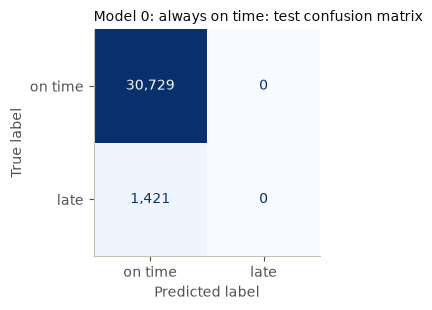

valid_pr_auc             0.1288
test_pr_auc              0.0442
test_roc_auc             0.5000
threshold                0.5000
accuracy                 0.9558
precision                0.0000
recall                   0.0000
f1                       0.0000
flagged_pct              0.0000
tp                       0.0000
fp                       0.0000
fn                    1421.0000
tn                   30729.0000
cost_vs_flag_none        1.0000
dtype: float64

In [5]:
p_va_zero, p_te_zero = np.zeros(len(y_va)), np.zeros(len(y_te))
evaluate_model("Model 0: always on time", p_va_zero, p_te_zero, threshold=0.5)

**Reading it:** high accuracy, zero recall: it never catches a late order. Any model must be judged on how it finds the rare late orders (precision, recall, F1, PR-AUC), not on accuracy.

## 5. Model 1: simple one-feature rule

A business rule of thumb: **rank orders by a single number** (e.g. "the farther the seller, the riskier"). Each candidate rule's direction and missing-value fill are learned on training data; the best rule is picked on validation, the same protocol as the real models.

In [6]:
rule_table, best_rule = rule_baselines(x_tr, y_tr, x_va, y_va, NUMERIC_FEATURES)
print(
    f"best single-feature rule on validation: {best_rule['feature']} "
    f"({'higher' if best_rule['direction'] > 0 else 'lower'} = riskier)"
)
rule_table.head(8).round(4)

best single-feature rule on validation: distance_km (higher = riskier)


,feature,higher_means,valid_pr_auc
0,distance_km,more risk,0.1740
1,freight_value,more risk,0.1614
2,same_state,less risk,0.1593
3,seller_late_rate_90d,more risk,0.1493
4,seller_prior_late_rate,more risk,0.1458
5,order_value,more risk,0.1403
6,total_volume_cm3,more risk,0.1344
7,total_weight_g,more risk,0.1341


Model 1: rule (distance_km): threshold 1161 (chosen on validation)

              precision    recall  f1-score   support

     on time      0.961     0.882     0.920     30729
        late      0.084     0.236     0.124      1421

    accuracy                          0.853     32150
   macro avg      0.523     0.559     0.522     32150
weighted avg      0.923     0.853     0.885     32150



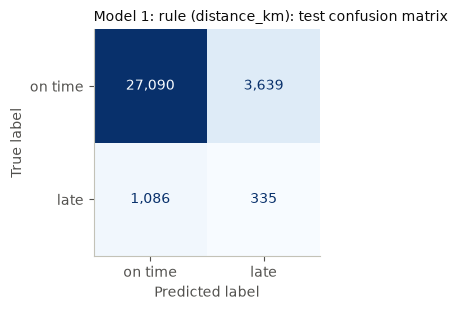

valid_pr_auc             0.1740
test_pr_auc              0.0588
test_roc_auc             0.5288
threshold             1160.8518
accuracy                 0.8530
precision                0.0843
recall                   0.2357
f1                       0.1242
flagged_pct             12.3608
tp                     335.0000
fp                    3639.0000
fn                    1086.0000
tn                   27090.0000
cost_vs_flag_none        1.2764
dtype: float64

In [7]:
p_va_rule, p_te_rule = rule_score(x_va, best_rule), rule_score(x_te, best_rule)
th_rule = choose_threshold(y_va, p_va_rule, COST_FN, COST_FP)["threshold"]
evaluate_model(f"Model 1: rule ({best_rule['feature']})", p_va_rule, p_te_rule, th_rule)

**Reading it:** the rule is simply "flag the order if the seller is more than about 1,161 km from the customer". On test it catches 23.6% of late orders with 8.4% precision (F1 0.124). It's easy to explain to a manager, and it's the benchmark the trained models must beat.

## 6. Model 2: logistic regression

Median imputation + missing-value flags, scaling and one-hot encoding (all fitted on training data only) feeding a logistic regression. **Tuned on validation:** regularisation strength C and class weighting.

In [8]:
logreg, logreg_grid = tune_logreg(x_tr, y_tr, x_va, y_va)
logreg_grid

,C,class_weight,valid_pr_auc
0,0.01,none,0.284021
1,0.10,none,0.275171
2,1.00,none,0.267141
3,0.01,balanced,0.267131
4,0.10,balanced,0.252280
5,1.00,balanced,0.247556


Model 2: logistic regression: threshold 0.04497 (chosen on validation)

              precision    recall  f1-score   support

     on time      0.974     0.741     0.842     30729
        late      0.094     0.578     0.161      1421

    accuracy                          0.734     32150
   macro avg      0.534     0.660     0.502     32150
weighted avg      0.935     0.734     0.812     32150



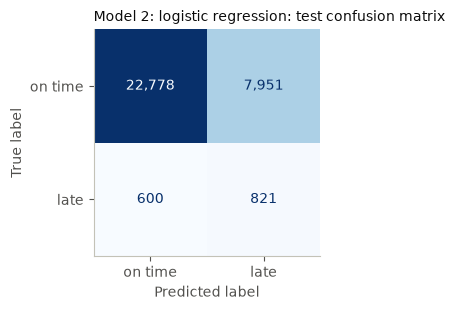

valid_pr_auc             0.2840
test_pr_auc              0.0943
test_roc_auc             0.7268
threshold                0.0450
accuracy                 0.7340
precision                0.0936
recall                   0.5778
f1                       0.1611
flagged_pct             27.2846
tp                     821.0000
fp                    7951.0000
fn                     600.0000
tn                   22778.0000
cost_vs_flag_none        1.5413
dtype: float64

In [9]:
model = attach_train_mean(logreg, x_tr)  # training means are the SHAP baseline (section 11)
p_va_lr, p_te_lr = model.predict_proba(x_va)[:, 1], model.predict_proba(x_te)[:, 1]
chosen = choose_threshold(y_va, p_va_lr, COST_FN, COST_FP)
evaluate_model("Model 2: logistic regression", p_va_lr, p_te_lr, chosen["threshold"])

In [10]:
# For comparison: the same model at the textbook default threshold of 0.5
n_over = (p_te_lr >= 0.5).sum()
print(f"test orders with predicted probability >= 0.5: {n_over:,} of {len(p_te_lr):,}")
pd.Series(classification_summary(y_te, p_te_lr, 0.5, COST_FN, COST_FP)).round(4)

test orders with predicted probability >= 0.5: 0 of 32,150


accuracy                 0.9558
precision                0.0000
recall                   0.0000
f1                       0.0000
flagged_pct              0.0000
tp                       0.0000
fp                       0.0000
fn                    1421.0000
tn                   30729.0000
cost_vs_flag_none        1.0000
dtype: float64

**Reading it:** at the cost-based threshold (0.045) logistic regression catches 57.8% of late orders with 9.4% precision (F1 0.161). At the textbook default of 0.5 it flags **no orders at all** (no predicted probability reaches 0.5 when only ~4-6% of orders are late), so it becomes identical to Model 0. **For rare events the threshold must come from the business costs, not from 0.5.**

## 7. Model 3: LightGBM

Gradient-boosted trees with native categorical handling. **Tuned on validation:** 24 configurations (leaves, minimum leaf size, class weighting), each with early stopping on validation PR-AUC.

In [11]:
lgbm, lgbm_grid = tune_lgbm(x_tr, y_tr, x_va, y_va)
lgbm_grid.head(8)

,num_leaves,min_child_samples,class_weighted,best_iteration,valid_pr_auc
0,15,20,True,7,0.212975
1,15,100,True,7,0.209720
2,63,500,True,11,0.208830
3,31,100,True,11,0.206884
4,15,500,True,7,0.202464
5,63,100,True,11,0.200419
6,31,20,True,11,0.196839
7,63,20,True,14,0.196108


Model 3: LightGBM: threshold 0.1338 (chosen on validation)

              precision    recall  f1-score   support

     on time      0.966     0.781     0.864     30729
        late      0.077     0.397     0.129      1421

    accuracy                          0.764     32150
   macro avg      0.521     0.589     0.497     32150
weighted avg      0.926     0.764     0.831     32150



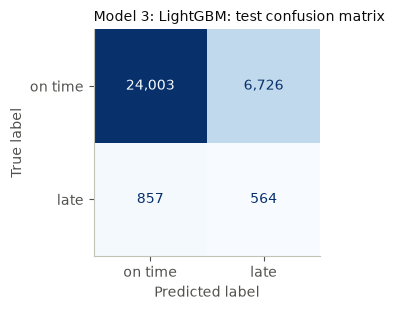

valid_pr_auc             0.2130
test_pr_auc              0.0725
test_roc_auc             0.6355
threshold                0.1338
accuracy                 0.7641
precision                0.0774
recall                   0.3969
f1                       0.1295
flagged_pct             22.6750
tp                     564.0000
fp                    6726.0000
fn                     857.0000
tn                   24003.0000
cost_vs_flag_none        1.5498
dtype: float64

In [12]:
p_va_gbm, p_te_gbm = lgbm.predict_proba(x_va)[:, 1], lgbm.predict_proba(x_te)[:, 1]
th_gbm = choose_threshold(y_va, p_va_gbm, COST_FN, COST_FP)["threshold"]
evaluate_model("Model 3: LightGBM", p_va_gbm, p_te_gbm, th_gbm)

**Reading it:** LightGBM catches 39.7% of late orders with 7.7% precision (F1 0.130): better than the rule on recall and PR-AUC, but below logistic regression on every ranking metric.

**Why does LightGBM struggle here?** Its early stopping halts after a handful of trees: patterns learned on 2017 stop helping on 2018 almost immediately. Trees also can't extrapolate. The validation period's platform late rate (`market_late_rate_30d`) is far above anything seen in training, and a tree treats every value above its largest training split the same way. A linear model extends the trend.

## 8. All models compared

**Selection rule:** the model with the highest **validation** PR-AUC is selected (chosen before looking at test). The test columns show how each would have performed.

In [13]:
comparison = pd.DataFrame(results).T
cols = [
    "valid_pr_auc",
    "test_pr_auc",
    "test_roc_auc",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "flagged_pct",
    "cost_vs_flag_none",
]
selected_name = comparison["valid_pr_auc"].drop("Model 0: always on time").idxmax()
print("selected on validation PR-AUC:", selected_name)
assert selected_name == "Model 2: logistic regression", "text below assumes logistic regression"
comparison[cols].astype(float).round(4)

selected on validation PR-AUC: Model 2: logistic regression


,valid_pr_auc,test_pr_auc,test_roc_auc,accuracy,precision,recall,f1,flagged_pct,cost_vs_flag_none
Model 0: always on time,0.1288,0.0442,0.5000,0.9558,0.0000,0.0000,0.0000,0.0000,1.0000
Model 1: rule (distance_km),0.1740,0.0588,0.5288,0.8530,0.0843,0.2357,0.1242,12.3608,1.2764
Model 2: logistic regression,0.2840,0.0943,0.7268,0.7340,0.0936,0.5778,0.1611,27.2846,1.5413
Model 3: LightGBM,0.2130,0.0725,0.6355,0.7641,0.0774,0.3969,0.1295,22.6750,1.5498


### 8b. Are the differences real? Paired bootstrap confidence intervals

Resample the test orders 1,000 times (seed 42), using the **same** orders for every model in each resample, and recompute PR-AUC. If a difference's 95% interval excludes 0, the gap is unlikely to be luck.

In [14]:
boot = bootstrap_pr_auc(
    y_te,
    {
        "logistic regression": p_te_lr,
        "LightGBM": p_te_gbm,
        f"rule: {best_rule['feature']}": p_te_rule,
    },
)
boot.round(4)

,pr_auc,ci_low,ci_high,diff_vs_logistic regression_low,diff_vs_logistic regression_high
model,,,,,
logistic regression,0.0943,0.0873,0.1035,0.0000,0.0000
LightGBM,0.0725,0.0666,0.0791,-0.0289,-0.0159
rule: distance_km,0.0588,0.0539,0.0653,-0.0432,-0.0293


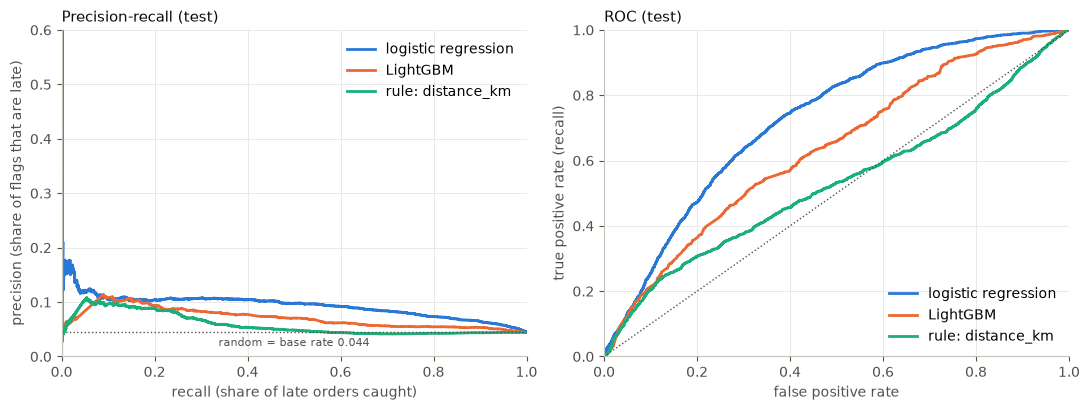

In [15]:
curves = [
    ("logistic regression", p_te_lr, BLUE),
    ("LightGBM", p_te_gbm, ORANGE),
    (f"rule: {best_rule['feature']}", p_te_rule, AQUA),
]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p, color in curves:
    prec, rec, _ = precision_recall_curve(y_te, p)
    fpr, tpr, _ = roc_curve(y_te, p)
    ax1.plot(rec, prec, color=color, linewidth=2, label=name)
    ax2.plot(fpr, tpr, color=color, linewidth=2, label=name)
ax1.axhline(y_te.mean(), color=INK2, linewidth=1, linestyle=":")
ax1.text(
    0.5,
    y_te.mean() - 0.025,
    f"random = base rate {y_te.mean():.3f}",
    ha="center",
    fontsize=8,
    color=INK2,
)
ax1.set(
    xlabel="recall (share of late orders caught)",
    ylabel="precision (share of flags that are late)",
    xlim=(0, 1),
    ylim=(0, 0.6),
)
ax1.set_title("Precision-recall (test)", loc="left", color=INK, fontsize=11)
ax2.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle=":")
ax2.set(xlabel="false positive rate", ylabel="true positive rate (recall)")
ax2.set(xlim=(0, 1), ylim=(0, 1))
ax2.set_title("ROC (test)", loc="left", color=INK, fontsize=11)
ax1.legend(loc="upper right")
ax2.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIG_DIR / "model_pr_curve_test.png", dpi=150)
plt.show()

In [16]:
# Ranking usefulness of the selected model: precision among the k% highest-risk orders
def precision_at_top(y, p, share):
    n = max(1, int(round(share * len(p))))
    return y[np.argsort(-p)[:n]].mean()


topk = pd.DataFrame(
    {
        f"top {int(s * 100)}%": {
            "valid precision": precision_at_top(y_va, p_va_lr, s),
            "test precision": precision_at_top(y_te, p_te_lr, s),
        }
        for s in (0.01, 0.05, 0.10, 0.20)
    }
).T
topk["test lift vs base rate"] = topk["test precision"] / y_te.mean()
topk.round(3)

,valid precision,test precision,test lift vs base rate
top 1%,0.388,0.140,3.162
top 5%,0.396,0.106,2.406
top 10%,0.357,0.105,2.386
top 20%,0.301,0.102,2.298


**Reading it:**

- **Accuracy ranks the models backwards.** Model 0, which never catches a late order, has the highest accuracy (95.6%). That's why PR-AUC and F1 for the late class are used.
- **Logistic regression is best on every ranking metric:** validation PR-AUC 0.284, test PR-AUC 0.094 [95% CI 0.087-0.104], ROC-AUC 0.727, F1 0.161, recall 57.8%. Both differences in the bootstrap exclude 0: LightGBM is lower by 0.016-0.029 and the distance rule by 0.029-0.043. So **logistic regression > LightGBM > simple rule > random** is not luck.
- **Useful as a ranking:** its riskiest 1% of test orders are late 14.0% of the time, 3.2× the base rate.
- **Honest caveat:** at thresholds chosen on validation, *no* model beats "flag nothing" on the calmer test period (cost 1.28-1.55×). The rule looks least bad only because it flags fewer orders. Section 9 explains why.

## 9. Threshold deep-dive (selected model)

The 5:1 cost ratio is an assumption, so the sensitivity to 3:1 and 10:1 is shown too.

In [17]:
print({k: round(v, 4) for k, v in chosen.items()})
sens = []
for ratio in (3, 5, 10):
    th = choose_threshold(y_va, p_va_lr, ratio, 1)
    te = confusion_at(y_te, p_te_lr, th["threshold"], ratio, 1)
    sens.append(
        {
            "FN:FP cost": f"{ratio}:1",
            "threshold (from valid)": th["threshold"],
            "valid cost / flag-none": th["cost"] / th["cost_flag_none"],
            "test precision": te["precision"],
            "test recall": te["recall"],
            "test flagged %": te["flagged_pct"],
            "test cost / flag-none": te["cost"] / te["cost_flag_none"],
        }
    )
sensitivity = pd.DataFrame(sens).set_index("FN:FP cost")
sensitivity.round(3)

{'threshold': 0.045, 'cost': 9892.0, 'precision': 0.2966, 'recall': 0.4859, 'cost_flag_none': 13285.0, 'cost_flag_all': 17970.0}


,threshold (from valid),valid cost / flag-none,test precision,test recall,test flagged %,test cost / flag-none
FN:FP cost,,,,,,
3:1,0.055,0.865,0.103,0.420,17.975,1.795
5:1,0.045,0.745,0.094,0.578,27.285,1.541
10:1,0.030,0.545,0.071,0.830,51.434,1.250


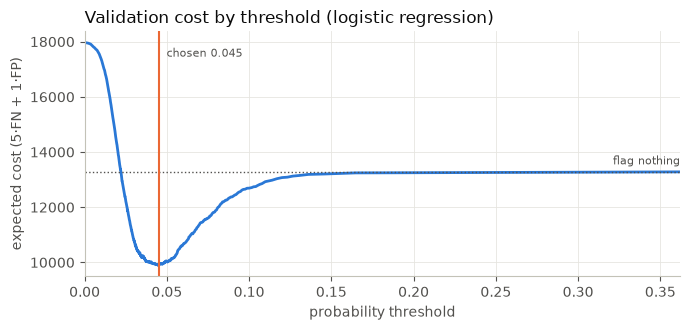

In [18]:
curve = cost_curve(y_va, p_va_lr, COST_FN, COST_FP)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(curve["threshold"], curve["cost"], color=BLUE, linewidth=2)
ax.axhline(chosen["cost_flag_none"], color=INK2, linestyle=":", linewidth=1)
ax.text(
    curve["threshold"].max(),
    chosen["cost_flag_none"] * 1.02,
    "flag nothing",
    ha="right",
    fontsize=8,
    color=INK2,
)
ax.axvline(chosen["threshold"], color=ORANGE, linewidth=1.5)
ax.text(
    chosen["threshold"],
    ax.get_ylim()[1] * 0.95,
    f"  chosen {chosen['threshold']:.3f}",
    fontsize=8,
    color=INK2,
)
ax.set_xlabel("probability threshold")
ax.set_ylabel(f"expected cost ({int(COST_FN)}·FN + {int(COST_FP)}·FP)")
ax.set_xlim(0, min(0.6, curve["threshold"].max()))
ax.set_title("Validation cost by threshold (logistic regression)", loc="left", color=INK)
plt.tight_layout()
fig.savefig(FIG_DIR / "model_cost_curve_valid.png", dpi=150)
plt.show()
test_cm = confusion_at(y_te, p_te_lr, chosen["threshold"], COST_FN, COST_FP)

**Reading it (honest version):** on validation the cost-based threshold beats doing nothing (cost 0.745× of flagging nothing). Applied unchanged to the calmer test period (late rate 4.42% vs 12.88%), the same threshold flags 27.3% of orders at 9.4% precision and costs **1.54× more than flagging nothing**, and the same happens at 3:1 and 10:1. At a 5:1 cost ratio a flag pays off only above 1/(1+5) ≈ 17% precision, and even the riskiest 1% of test orders reach only 14.0%. The *ranking* still works (2.1-3.2× lift over the base rate at every top-k level), but **a fixed threshold doesn't survive a three-fold drop in the late rate.** In production the threshold has to be re-set as the base rate moves (e.g. monthly on the latest labelled month), or the model used as a top-k priority list for low-cost actions.

## 10. Error analysis: where does the selected model miss?

Using the test period and the chosen threshold: (a) by purchase month, (b) by customer state, (c) how the late orders the model **missed** differ from the ones it **caught**.

In [19]:
test_rows = table[table["split"] == "test"].reset_index(drop=True)
months = test_rows["purchase_ts"].dt.strftime("%Y-%m")
by_month = segment_metrics(months, y_te, p_te_lr, chosen["threshold"])
by_month.round(3)

,orders,late,late_rate,mean_predicted,recall,precision,pr_auc
segment,,,,,,,
2018-04,6798,306,0.045,0.028,0.500,0.171,0.181
2018-05,6749,443,0.066,0.034,0.472,0.152,0.151
2018-06,6096,71,0.012,0.028,0.437,0.037,0.058
2018-07,6156,208,0.034,0.048,0.639,0.054,0.075
2018-08,6351,393,0.062,0.053,0.751,0.092,0.089


In [20]:
states = test_rows["customer_state"].astype(str)
by_state = segment_metrics(states, y_te, p_te_lr, chosen["threshold"])
by_state.sort_values("late", ascending=False).head(10).round(3)

,orders,late,late_rate,mean_predicted,recall,precision,pr_auc
segment,,,,,,,
SP,14752,592,0.040,0.029,0.478,0.134,0.132
RJ,3749,163,0.043,0.053,0.791,0.072,0.099
BA,1054,114,0.108,0.065,0.798,0.120,0.118
MG,3584,109,0.030,0.025,0.183,0.058,0.060
ES,620,57,0.092,0.051,0.684,0.122,0.140
PR,1636,44,0.027,0.031,0.295,0.047,0.050
PE,522,41,0.079,0.070,0.878,0.093,0.094
RS,1600,40,0.025,0.037,0.275,0.027,0.054
CE,379,32,0.084,0.069,0.844,0.099,0.140


In [21]:
late_mask = y_te == 1
caught = late_mask & (p_te_lr >= chosen["threshold"])
missed = late_mask & (p_te_lr < chosen["threshold"])
compare_cols = [
    "promised_days",
    "distance_km",
    "same_state",
    "seller_late_rate_90d",
    "market_late_rate_30d",
    "freight_value",
    "total_weight_g",
]
missed_vs_caught = pd.DataFrame(
    {
        "caught (median)": test_rows.loc[caught, compare_cols].median(),
        "missed (median)": test_rows.loc[missed, compare_cols].median(),
        "on-time (median)": test_rows.loc[~late_mask, compare_cols].median(),
    }
)
print(
    f"late test orders: {late_mask.sum():,} | caught: {caught.sum():,} | missed: {missed.sum():,}"
)
missed_vs_caught.round(3)

late test orders: 1,421 | caught: 821 | missed: 600


,caught (median),missed (median),on-time (median)
promised_days,18.000,18.000,22.000
distance_km,667.415,318.983,396.473
same_state,0.000,0.000,0.000
seller_late_rate_90d,0.062,0.053,0.059
market_late_rate_30d,0.049,0.096,0.075
freight_value,19.440,16.390,18.380
total_weight_g,700.000,650.000,696.000


**Reading it:**

- **By month:** the model ranks best in Apr-May 2018 (PR-AUC 0.15-0.18) and worst in June, when only 1.2% of orders were late and precision at the threshold fell to 3.7%. Fewer late orders means a fixed threshold produces mostly false alarms, the base-rate problem from section 9.
- **By state:** it catches most late orders in the North-East (e.g. PE 87.8%, CE 84.4%, BA 79.8%) but few in MG (18.3%), RS (27.5%) and PR (29.5%), where late orders are rarer and look like on-time ones.
- **Missed vs caught:** the late orders it misses are **short-distance** (median 319 km vs 667 km for caught ones; on-time orders 396 km) and were placed when the **platform late rate was high** (median 9.6% vs 4.9%). The first suggests local disruptions that purchase-time data can't see. The second matches the known weakness: the linear weight on `market_late_rate_30d` is negative (inverted-U pattern in training), so the model *under*-predicts during delay waves.
- **What would help:** a non-linear treatment of the platform late rate (bins or a spline), and a second model at dispatch time with carrier information.

## 11. Explainability (SHAP)

For a linear model, SHAP values are exact: contribution = coefficient × (transformed value − training mean), in log-odds. One-hot and missing-flag columns are summed back to their original feature. The first cell cross-checks the implementation against the `shap` library.

In [22]:
contrib_te = linear_contributions(model, x_te)
pre, lr = model.named_steps["pre"], model.named_steps["model"]


def dense(m):
    return np.asarray(m.toarray() if hasattr(m, "toarray") else m)


z_tr, z_te = dense(pre.transform(x_tr)), dense(pre.transform(x_te.iloc[:500]))
explainer = shap.LinearExplainer(lr, shap.maskers.Independent(z_tr, max_samples=len(x_tr)))
ours = (z_te - model.train_mean_) * lr.coef_[0]
print(f"max |ours - shap library| = {np.abs(ours - explainer.shap_values(z_te)).max():.2e}")
logit = np.log(p_te_lr / (1 - p_te_lr))
baseline = lr.intercept_[0] + (model.train_mean_ * lr.coef_[0]).sum()
err = np.abs(baseline + contrib_te.sum(axis=1).to_numpy() - logit).max()
print(f"max |baseline + sum(contrib) - logit| = {err:.2e}")

max |ours - shap library| = 0.00e+00
max |baseline + sum(contrib) - logit| = 2.66e-15


constant in the test period (offset only): ['is_nov_dec']


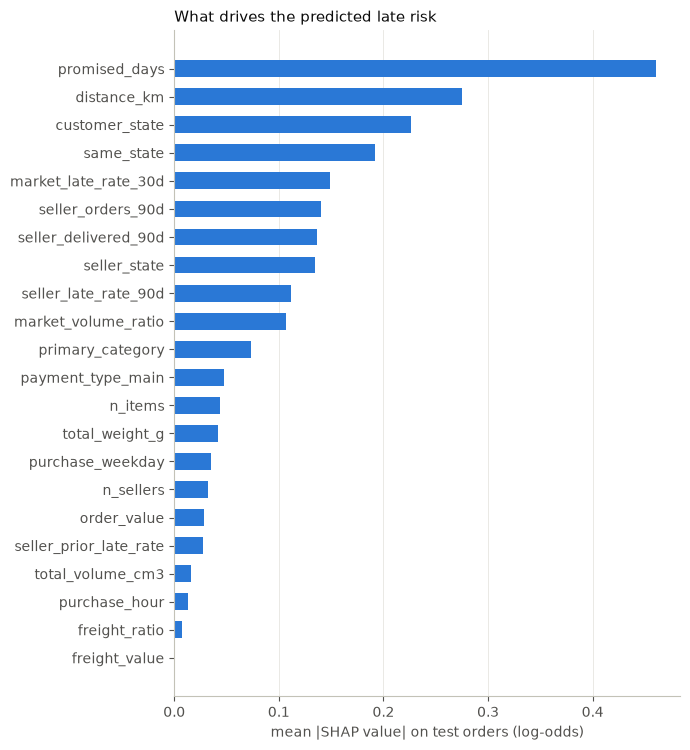

promised_days           0.460
distance_km             0.275
customer_state          0.227
same_state              0.192
market_late_rate_30d    0.149
seller_orders_90d       0.140
seller_delivered_90d    0.136
seller_state            0.134
seller_late_rate_90d    0.112
market_volume_ratio     0.106
dtype: float64

In [23]:
# Features constant in the test period only shift every test order by the same amount,
# so they can't separate risky from safe orders there; they're left off this chart.
constant_in_test = [f for f in FEATURES if x_te[f].nunique(dropna=False) <= 1]
print("constant in the test period (offset only):", constant_in_test)
importance = contrib_te.drop(columns=constant_in_test).abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 0.3 * len(importance) + 1))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_xlabel("mean |SHAP value| on test orders (log-odds)")
ax.grid(axis="y", visible=False)
ax.set_title("What drives the predicted late risk", loc="left", color=INK, fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "model_shap_importance.png", dpi=150)
plt.show()
importance.sort_values(ascending=False).round(3).head(10)

In [24]:
# Direction of each main numeric effect, measured on TRAINING orders (where every feature varies)
contrib_tr = linear_contributions(model, x_tr)
ranked = importance.sort_values(ascending=False).index
top_numeric = [f for f in ranked if f in NUMERIC_FEATURES][:6]
sign = {f: np.corrcoef(x_tr[f].fillna(x_tr[f].median()), contrib_tr[f])[0, 1] for f in top_numeric}
pd.DataFrame(
    {
        "mean |SHAP| (test)": importance[top_numeric],
        "higher value ->": ["more risk" if sign[f] > 0 else "less risk" for f in top_numeric],
    }
).round(3)

,mean |SHAP| (test),higher value ->
promised_days,0.460,less risk
distance_km,0.275,more risk
same_state,0.192,less risk
market_late_rate_30d,0.149,less risk
seller_orders_90d,0.140,more risk
seller_delivered_90d,0.136,less risk


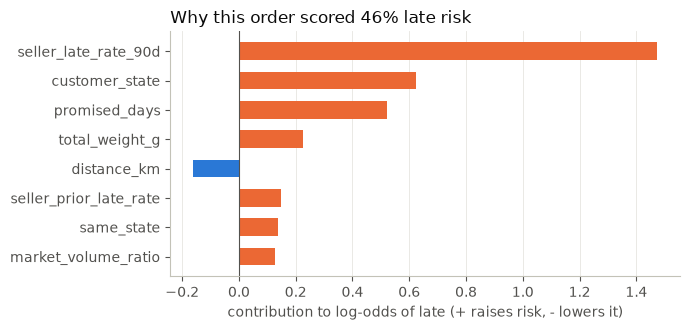

seller_late_rate_90d            1.0
customer_state                   RJ
promised_days                    16
total_weight_g              16500.0
distance_km               366.06814
seller_prior_late_rate          0.5
same_state                        0
market_volume_ratio        1.272384
Name: 92108, dtype: object

In [25]:
# One high-risk test order explained (the "waterfall" the app will show)
i = int(np.argmax(p_te_lr))
row = (
    contrib_te.drop(columns=constant_in_test)
    .iloc[i]
    .sort_values(key=np.abs, ascending=False)
    .head(8)[::-1]
)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(row.index, row.values, color=[ORANGE if v > 0 else BLUE for v in row.values], height=0.6)
ax.axvline(0, color=INK2, linewidth=0.8)
ax.set_xlabel("contribution to log-odds of late (+ raises risk, - lowers it)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Why this order scored {p_te_lr[i]:.0%} late risk", loc="left", color=INK)
plt.tight_layout()
fig.savefig(FIG_DIR / "model_example_explanation.png", dpi=150)
plt.show()
x_te.iloc[i][row.index[::-1]]

## 12. Save the model and write `fact_order_risk`

In [26]:
MODEL_VERSION = "logreg_v1_2026-10-19"


def period(split):
    s = table.loc[table.split == split, "purchase_ts"]
    return [str(s.min()), str(s.max())]


metadata = {
    "model_version": MODEL_VERSION,
    "model_type": "LogisticRegression (sklearn pipeline: impute + scale + one-hot)",
    "params": {k: model.named_steps["model"].get_params()[k] for k in ("C", "class_weight")},
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "train_period": period("train"),
    "valid_period": period("valid"),
    "test_period": period("test"),
    "threshold": chosen["threshold"],
    "cost_fn": COST_FN,
    "cost_fp": COST_FP,
    "valid_metrics": evaluate(y_va, p_va_lr),
    "test_metrics": evaluate(y_te, p_te_lr),
    "test_at_threshold": {k: float(v) for k, v in test_cm.items()},
    "model_comparison_test": comparison[cols].astype(float).round(4).to_dict(orient="index"),
    "seed": 42,
}
model_path, meta_path = save_artifacts(model, metadata)
print(model_path.name, meta_path.name)

late_delivery_model.pkl metadata.json


In [27]:
p_all = model.predict_proba(table[FEATURES])[:, 1]
contrib_all = linear_contributions(model, table[FEATURES])
risk = pd.DataFrame(
    {
        "order_id": table["order_id"].to_numpy(),
        "split": table["split"].to_numpy(),
        "late_probability": p_all.round(4),
        "risk_band": risk_band(p_all, chosen["threshold"]),
        "model_version": MODEL_VERSION,
        "top_shap_features": top_drivers(contrib_all, k=3),
    }
)
risk_path = ROOT / "models" / "order_risk_scores.parquet"
risk.to_parquet(risk_path, index=False)
with connect(read_only=False) as con:
    con.execute(
        "CREATE OR REPLACE TABLE fact_order_risk AS SELECT * FROM read_parquet(?)", [str(risk_path)]
    )
    print(
        con.execute(
            "SELECT split, risk_band, COUNT(*) AS orders FROM fact_order_risk "
            "GROUP BY ALL ORDER BY split, risk_band"
        ).df()
    )
risk.head(3)

   split risk_band  orders
0   test      high    8772
1   test       low   10140
2   test    medium   13238
3  train      high   19049
4  train       low    8034
5  train    medium   16343
6  valid      high    4353
7  valid       low    6835
8  valid    medium    9439


,order_id,split,late_probability,risk_band,model_version,top_shap_features
0,ec7a019261fce44180373d45b442d78f,train,0.0021,low,logreg_v1_2026-10-19,market_volume_ratio (-0.87); market_late_rate_...
1,b95a0a8bd30aece4e94e81f0591249d8,train,0.0064,low,logreg_v1_2026-10-19,promised_days (-0.77); market_volume_ratio (+0...
2,38bcb524e1c38c2c1b60600a80fc8999,train,0.0090,low,logreg_v1_2026-10-19,market_volume_ratio (+1.21); promised_days (-0...


## 13. Limitations and next steps

- **Drift dominates.** The late rate swings from ~4% to ~13% between quarters; any fixed threshold needs re-setting. Monitor the base rate and recalibrate monthly.
- **Moderate signal.** Purchase-time data can't see carrier problems or weather; most of the risk is decided after purchase.
- **Linear limits.** In training, the platform late rate relates to lateness as an inverted U (quintile late rates 3.5% / 4.1% / 9.1% / 8.2% / 3.5%) and overlaps with the holiday flag (r = 0.30), so its linear weight is negative. Binning it, or a tree model once there's more stable history, could capture this.
- **Single split.** Results come from one train/valid/test split; a rolling backtest over several periods would show how stable they are.
- **Survivorship.** Orders still undelivered at the data cut-off (1-3% per month) have no label and are excluded.
- **Scores for train/valid orders are in-sample.** Use `split = 'test'` in `fact_order_risk` for honest dashboards.
- **Transparency:** during development an earlier feature set (all-time seller counts instead of rolling windows) was also scored on the test period once, before drift was diagnosed. All the choices recorded here were made on validation.
- **Next:** the risk table feeds Power BI (Day 4) and the Streamlit risk page (Day 6).